In [1]:
import yfinance as yf
import numpy as np 
import pandas as pd

In [2]:
tickers = [
    "ADI", # Analog Devices, Inc.
    "ADM", # Archer-Daniels-Midland Company
    "JPM", # JPMorgan Chase & Co.
    "KO",  # The Coca-Cola Company
    "APA", # APA Corporation
    "AMAT",# Applied Materials, Inc.
    "NVDA",# NVIDIA Corporation
    "GLW", # Corning Incorporated
    "LLY", # Eli Lilly and Company 
    "FLEX" # Flex Ltd.
    ]

In [15]:
portfolio = yf.download(tickers,start="2026-01-01",auto_adjust=True)

c:\Users\vince\Portfolio_project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\vince\Portfolio_project\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\vince\Portfolio_project\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.sort_

In [16]:
portfolio['Close'].tail()

Ticker,ADI,ADM,AMAT,APA,FLEX,GLW,JPM,KO,LLY,NVDA
Date,,,,,,,,,,
2026-11-09,394.660004,69.839996,370.549988,44.549999,78.169998,115.678314,342.079987,96.029999,1410.238525,178.669998
2026-11-10,393.299988,69.300003,372.529999,45.119999,76.089996,111.867264,342.070007,96.910004,1430.553955,168.889999
2026-11-11,409.079987,70.919998,395.079987,46.740002,78.970001,120.177750,343.390015,97.570000,1435.547852,173.729996
2026-11-12,409.290009,70.970001,380.950012,47.660000,78.120003,119.219994,342.820007,97.440002,1425.550049,166.190002
2026-11-13,397.970001,72.900002,370.500000,48.439999,74.980003,114.080002,346.190002,99.250000,1443.500000,162.850006


In [17]:
portfolio = portfolio['Close']

In [18]:
port_returns = (portfolio/portfolio.shift(1)) - 1
port_returns

Ticker,ADI,ADM,AMAT,APA,FLEX,GLW,JPM,KO,LLY,NVDA
Date,,,,,,,,,,
2026-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-01-05,0.012968,0.008976,0.057463,-0.035095,-0.030308,-0.021837,0.026300,-0.017072,-0.035960,-0.003866
2026-01-06,0.056439,0.015274,0.041116,-0.024111,0.004858,0.006314,0.006225,-0.001472,0.021632,-0.004678
2026-01-07,-0.000171,-0.032567,-0.012871,-0.020519,-0.011120,-0.014118,-0.022773,-0.004422,0.041399,0.009987
2026-01-08,0.021407,0.045625,-0.036140,0.084652,-0.015971,-0.030231,0.008563,0.027095,-0.020666,-0.021522
...,...,...,...,...,...,...,...,...,...,...
2026-11-09,0.085543,-0.001858,0.113699,-0.001793,0.120235,0.092528,0.022691,0.003763,0.042799,-0.042703
2026-11-10,-0.003446,-0.007732,0.005343,0.012795,-0.026609,-0.032945,-0.000029,0.009164,0.014406,-0.054738
2026-11-11,0.040122,0.023377,0.060532,0.035904,0.037850,0.074289,0.003859,0.006810,0.003491,0.028658


In [ ]:
weights = np.array([0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1])
total_returns = np.prod(1 + port_returns,axis=0) - 1 #axis 0 is vertically (across time)
total_returns


Ticker
ADI     0.466827
ADM     0.260000
AMAT    0.382900
APA     0.964724
FLEX    0.177450
GLW     0.267817
JPM     0.084114
KO      0.463799
LLY     0.344213
NVDA   -0.135658
dtype: float64

In [ ]:
np.dot(total_returns,weights) #our equal weighted portfolio has returned us 32.76% from the beginning of the year

np.float64(0.32761875141604463)

<Axes: xlabel='Date'>

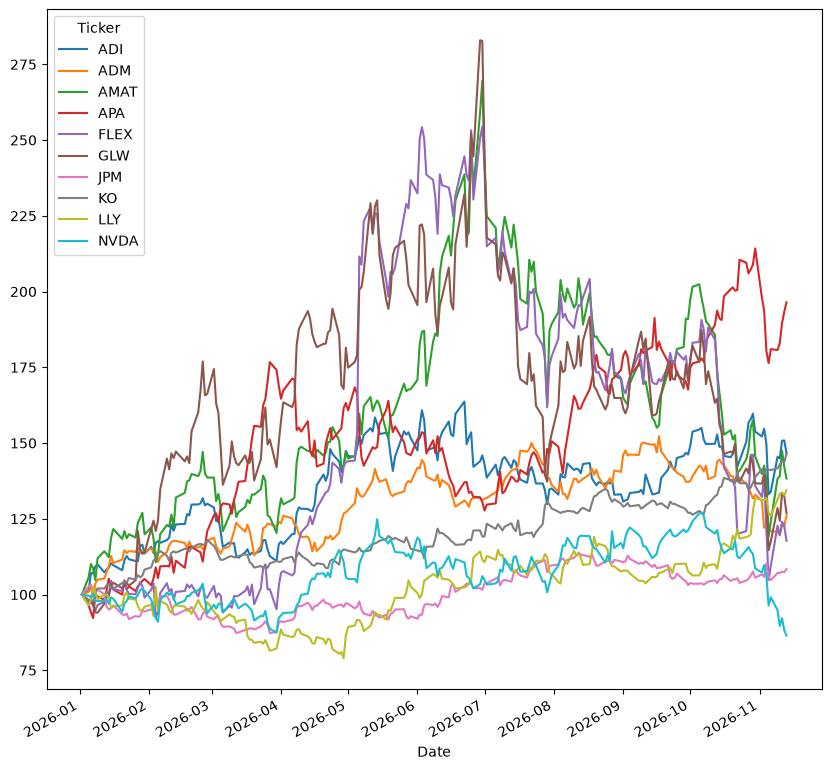

In [44]:
import matplotlib.pyplot as plt
(portfolio / portfolio.iloc[0]* 100).plot(figsize=(10,10))

In [46]:
risk_returns = np.log(portfolio / portfolio.shift(1))
risk_returns

Ticker,ADI,ADM,AMAT,APA,FLEX,GLW,JPM,KO,LLY,NVDA
Date,,,,,,,,,,
2026-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-01-05,0.012885,0.008935,0.055872,-0.035725,-0.030777,-0.022079,0.025960,-0.017219,-0.036623,-0.003873
2026-01-06,0.054904,0.015158,0.040293,-0.024407,0.004847,0.006294,0.006205,-0.001473,0.021401,-0.004689
2026-01-07,-0.000171,-0.033110,-0.012955,-0.020733,-0.011182,-0.014218,-0.023036,-0.004432,0.040565,0.009938
2026-01-08,0.021182,0.044615,-0.036809,0.081259,-0.016100,-0.030697,0.008527,0.026735,-0.020883,-0.021757
...,...,...,...,...,...,...,...,...,...,...
2026-11-09,0.082080,-0.001860,0.107687,-0.001794,0.113539,0.088494,0.022438,0.003756,0.041909,-0.043641
2026-11-10,-0.003452,-0.007762,0.005329,0.012713,-0.026969,-0.033500,-0.000029,0.009122,0.014303,-0.056293
2026-11-11,0.039338,0.023108,0.058771,0.035275,0.037151,0.071659,0.003851,0.006787,0.003485,0.028255


In [ ]:
port_risk = port_returns.std() * (250 ** 0.5)
port_risk

Ticker
ADI     0.405723
ADM     0.280845
AMAT    0.665437
APA     0.457194
FLEX    0.791056
GLW     0.803658
JPM     0.224961
KO      0.194971
LLY     0.366465
NVDA    0.395366
dtype: float64

In [55]:
np.dot(port_risk,weights) #shows our annualized volatility of our 10 stocks if there was no diversificatin

np.float64(0.45856758739887504)

In [54]:
cov_port = port_returns.cov() * 250
cov_port

Ticker,ADI,ADM,AMAT,APA,FLEX,GLW,JPM,KO,LLY,NVDA
Ticker,,,,,,,,,,
ADI,0.164611,0.002267,0.182006,-0.016477,0.188561,0.192973,0.021990,-0.016274,0.001935,0.064700
ADM,0.002267,0.078874,-0.008828,0.049112,-0.001843,0.000683,-0.000138,0.003979,-0.002293,-0.004592
AMAT,0.182006,-0.008828,0.442806,-0.046221,0.357571,0.398547,0.034387,-0.038534,-0.022445,0.125178
APA,-0.016477,0.049112,-0.046221,0.209026,-0.067439,-0.049876,-0.015364,0.001910,-0.005327,-0.028637
FLEX,0.188561,-0.001843,0.357571,-0.067439,0.625769,0.437063,0.037239,-0.038796,-0.037581,0.146993
GLW,0.192973,0.000683,0.398547,-0.049876,0.437063,0.645866,0.025034,-0.040211,-0.012736,0.139623
JPM,0.021990,-0.000138,0.034387,-0.015364,0.037239,0.025034,0.050608,-0.001986,0.009860,0.010920
KO,-0.016274,0.003979,-0.038534,0.001910,-0.038796,-0.040211,-0.001986,0.038014,0.015318,-0.022954
LLY,0.001935,-0.002293,-0.022445,-0.005327,-0.037581,-0.012736,0.009860,0.015318,0.134297,-0.018266


In [58]:
corr_port = port_returns.corr()
corr_port

Ticker,ADI,ADM,AMAT,APA,FLEX,GLW,JPM,KO,LLY,NVDA
Ticker,,,,,,,,,,
ADI,1.000000,0.019896,0.674138,-0.088825,0.587510,0.591828,0.240925,-0.205725,0.013014,0.403342
ADM,0.019896,1.000000,-0.047235,0.382492,-0.008297,0.003027,-0.002177,0.072673,-0.022283,-0.041359
AMAT,0.674138,-0.047235,1.000000,-0.151928,0.679280,0.745250,0.229712,-0.297003,-0.092041,0.475795
APA,-0.088825,0.382492,-0.151928,1.000000,-0.186468,-0.135745,-0.149377,0.021424,-0.031791,-0.158426
FLEX,0.587510,-0.008297,0.679280,-0.186468,1.000000,0.687488,0.209258,-0.251543,-0.129636,0.469990
GLW,0.591828,0.003027,0.745250,-0.135745,0.687488,1.000000,0.138469,-0.256629,-0.043245,0.439428
JPM,0.240925,-0.002177,0.229712,-0.149377,0.209258,0.138469,1.000000,-0.045279,0.119602,0.122772
KO,-0.205725,0.072673,-0.297003,0.021424,-0.251543,-0.256629,-0.045279,1.000000,0.214381,-0.297772
LLY,0.013014,-0.022283,-0.092041,-0.031791,-0.129636,-0.043245,0.119602,0.214381,1.000000,-0.126073


In [60]:
port_var = np.dot(weights.T,np.dot(port_returns.cov() *250, weights))
port_var

np.float64(0.06448244469129162)

In [ ]:
port_vol = port_var ** 0.5
port_vol #with diversification, the volatility went from 45.86% down to 25.39%
#nearly down 50% (huge risk reduction)

np.float64(0.2539339376516885)